In [8]:
#Thermompnn visualization: Table and heatmap script

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap



In [11]:
#First plot

#ddG heatmap data
#Define your directories

df_ddG = pd.read_csv('/projectbig/jupyternotebook/jrivera/data/thermompnn_data/ThermoMPNN_inference_3d_wt_esm3_large_PAH (1).csv')

#Reshape your data: extract the mutation, the position, and the predited ddG change
df_pivot = df_ddG.pivot(index='mutation', columns='position', values='ddG_pred')

df_pivot

position,0,1,2,3,4,5,6,7,8,9,...,442,443,444,445,446,447,448,449,450,451
mutation,,,,,,,,,,,,,,,,,,,,,
A,-0.033604,0.034568,-0.073005,0.000000,-0.121986,-0.013765,0.046302,0.107009,-0.205749,-0.243641,...,0.095354,0.323676,0.456256,-0.170116,0.000000,0.126495,-0.047781,-0.101127,0.124204,0.113330
C,-0.215144,-0.086966,-0.238267,-0.013370,-0.247236,-0.146381,0.078150,-0.033902,-0.231762,-0.247652,...,0.024812,0.040899,0.000000,-0.232525,-0.374005,-0.130565,-0.141897,-0.233221,-0.066978,0.077499
D,-0.069909,-0.090710,-0.189532,0.010941,-0.279674,0.004404,0.093526,-0.128944,-0.101127,-0.151829,...,0.275605,1.229014,0.926992,-0.056465,0.408705,0.717747,0.082342,0.036540,0.378858,0.824226
E,-0.027490,-0.064109,-0.142307,-0.014472,-0.249865,0.018347,0.000000,-0.073748,-0.233671,-0.265728,...,0.174956,0.882785,0.624179,-0.254037,0.121603,0.546428,-0.015045,-0.009355,0.258936,0.501588
F,0.076864,0.300929,0.119538,0.361424,0.032337,0.055204,0.385880,0.297662,-0.055613,-0.023445,...,0.127247,0.062405,-0.000485,-0.031833,-0.122740,-0.025222,0.067755,-0.021914,-0.031471,0.234811
G,0.078703,0.076030,-0.030656,0.177106,-0.031801,0.108638,0.347647,0.159118,0.010762,0.000000,...,0.486682,0.934025,0.985326,0.206067,0.477627,0.531306,0.150678,0.157926,0.341609,0.719433
H,0.062203,0.226001,0.059958,0.229315,0.016269,0.048058,0.310261,0.241409,-0.052938,-0.098464,...,0.214426,0.482087,0.382002,0.057497,0.114142,0.335140,0.090428,0.029462,0.201799,0.290468
I,-0.034604,0.241080,0.054613,0.246386,-0.001659,-0.007369,0.308560,0.302652,-0.103008,-0.152569,...,0.000000,-0.207696,-0.315956,-0.035935,-0.153119,0.013779,-0.009335,-0.066485,0.000000,-0.072472
K,0.151421,0.253583,0.161884,0.248173,0.007497,0.067159,0.279375,0.255150,-0.188290,-0.164568,...,0.113916,0.640803,0.659283,0.053035,0.322513,0.464369,0.022454,0.000000,0.225601,0.000000


In [12]:
#Second plot

#PAH variants: Data from UKE patients

# Open and read your csv file
df_PAH_variants = pd.read_csv('/projectbig/jupyternotebook/jrivera/data/PAH_variants_data/20250506_PAH-variants.csv',
                              skiprows=1, index_col=0)

#index_col = Here you can define which of your columns will be selected as your index colum (first colum, which gives your row names)


# Drop 'Unnamed' columns (if any)
# 1. Make sure your selected columns are strings
df_PAH_variants.columns = df_PAH_variants.columns.astype(str)  

#2. Select the columns that are not unnamed 
#____.loc selects the wished location you need to access: .loc[row, columns]
#____.columns : select columns
#    .str.contains (^Unnamed) : Boolean/evaluation wheather True or False 
#    ^ means 'start with'
# ~ means bitwise NOT operator, which means do the opposite: Turns True to False
df_PAH_variants = df_PAH_variants.loc[:, ~df_PAH_variants.columns.str.contains('^Unnamed')]


# Ensure all values are numeric (0/1), convert non-numeric to 0
#pd.to_numeric converts series/list to a numeric value 
#errors= '' : with this line you define how you want to deal with errors
#errors= 'raise': is the defaul setting and it shows you an error
#errors= 'ignore': it ignores it!
#errors= 'coerce': replaces uncoveritble values with NaN (Not a Number)
#.fillna(0).astype(int) if thjere is a NaN change it for a 0 that is defined as an interger number
df_PAH_variants = df_PAH_variants.apply(pd.to_numeric, errors='coerce').fillna(0).astype(int)

# Convert columns numbers to intergers if they are float numbers like "1.0" floats
df_PAH_variants.columns = df_PAH_variants.columns.astype(float).astype(int)

print(df_PAH_variants)

# Save your data as a CSV file
df_PAH_variants.to_csv('/projectbig/jupyternotebook/jrivera/output_clean/thermompnn_results/PAH_variant_UKE.csv')

           1    2    3    4    5    6    7    8    9    10   ...  443  444  \
Position                                                     ...             
Aminoacid    0    0    0    0    0    0    0    0    0    0  ...    0    0   
A            0    0    0    0    0    0    0    0    0    0  ...    0    0   
C            0    0    0    0    0    0    0    0    0    0  ...    0    0   
D            0    0    0    0    0    0    0    0    0    0  ...    0    0   
E            0    0    0    0    0    0    0    0    0    0  ...    0    0   
F            0    0    0    0    0    0    0    0    0    0  ...    0    0   
G            0    0    0    0    0    0    0    0    0    0  ...    0    0   
H            0    0    0    0    0    0    0    0    0    0  ...    0    0   
I            0    0    0    0    0    0    0    0    0    0  ...    0    0   
K            0    0    0    0    0    0    0    0    0    0  ...    0    0   
L            0    0    0    0    0    0    0    0    0    0  ...

In [13]:
#Thrid plot
#PAH domans

# Create a new panda data frame
df_domain = pd.DataFrame(columns=range(453)) 

# Define the to-be columns as a list of indices from 0 to 452 (AS of PAH)
PAH = list(range(453))

# Define your PAH domains dictionary
PAH_domains = {
    'DHM_N_terminal': PAH[0:20],
    'RS_PAH_SAI': PAH[20:32],
    'ACT_domian': PAH[32:109],
    'linker_MCI': PAH[109:128],
    'Active_site_lid': PAH[128:151],
    'Catalytic_domain_general': PAH[151:411],
    'C_terminal_o_d': PAH[411:424],
    'Variable_hinge': PAH[424:427],
    'C_terminal_helix': PAH[427:453]
}


# Convert your dictionary data into a vector. We need to have data as a vector because we use binary data for our heatmap and ML in general.
# Check if there are matches in your 'indices' of your table, and change the number from 0 to 1
#domain_name as my new defined key of my dictionary
#indices as my new defined items of my dictionary
#Here the order does matter! And also the calling of the .items()

#np.zeros: creates a numpy array with 453 positions that are filled up with 0s
#vector[indices] = 1: access the positions of the items of the dictionary and change the values to 1 in these positions
#df_domain.loc[domain_name] = vector: creates a new row of my pd data frame with the domain_names and then adds the binary vector on the empty pd data frame
for domain_name, indices in PAH_domains.items(): 
    vector= np.zeros(453)
    vector [indices] = 1
    df_domain.loc[domain_name]=vector

print(df_domain)


                          0    1    2    3    4    5    6    7    8    9    \
DHM_N_terminal            1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0   
RS_PAH_SAI                0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
ACT_domian                0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
linker_MCI                0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
Active_site_lid           0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
Catalytic_domain_general  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
C_terminal_o_d            0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
Variable_hinge            0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
C_terminal_helix          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

                          ...  443  444  445  446  447  448  449  450  451  \
DHM_N_terminal            ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
RS_PAH_SAI                ...  0.0  0.0  0.0  0.0  0.0  0.0  0.

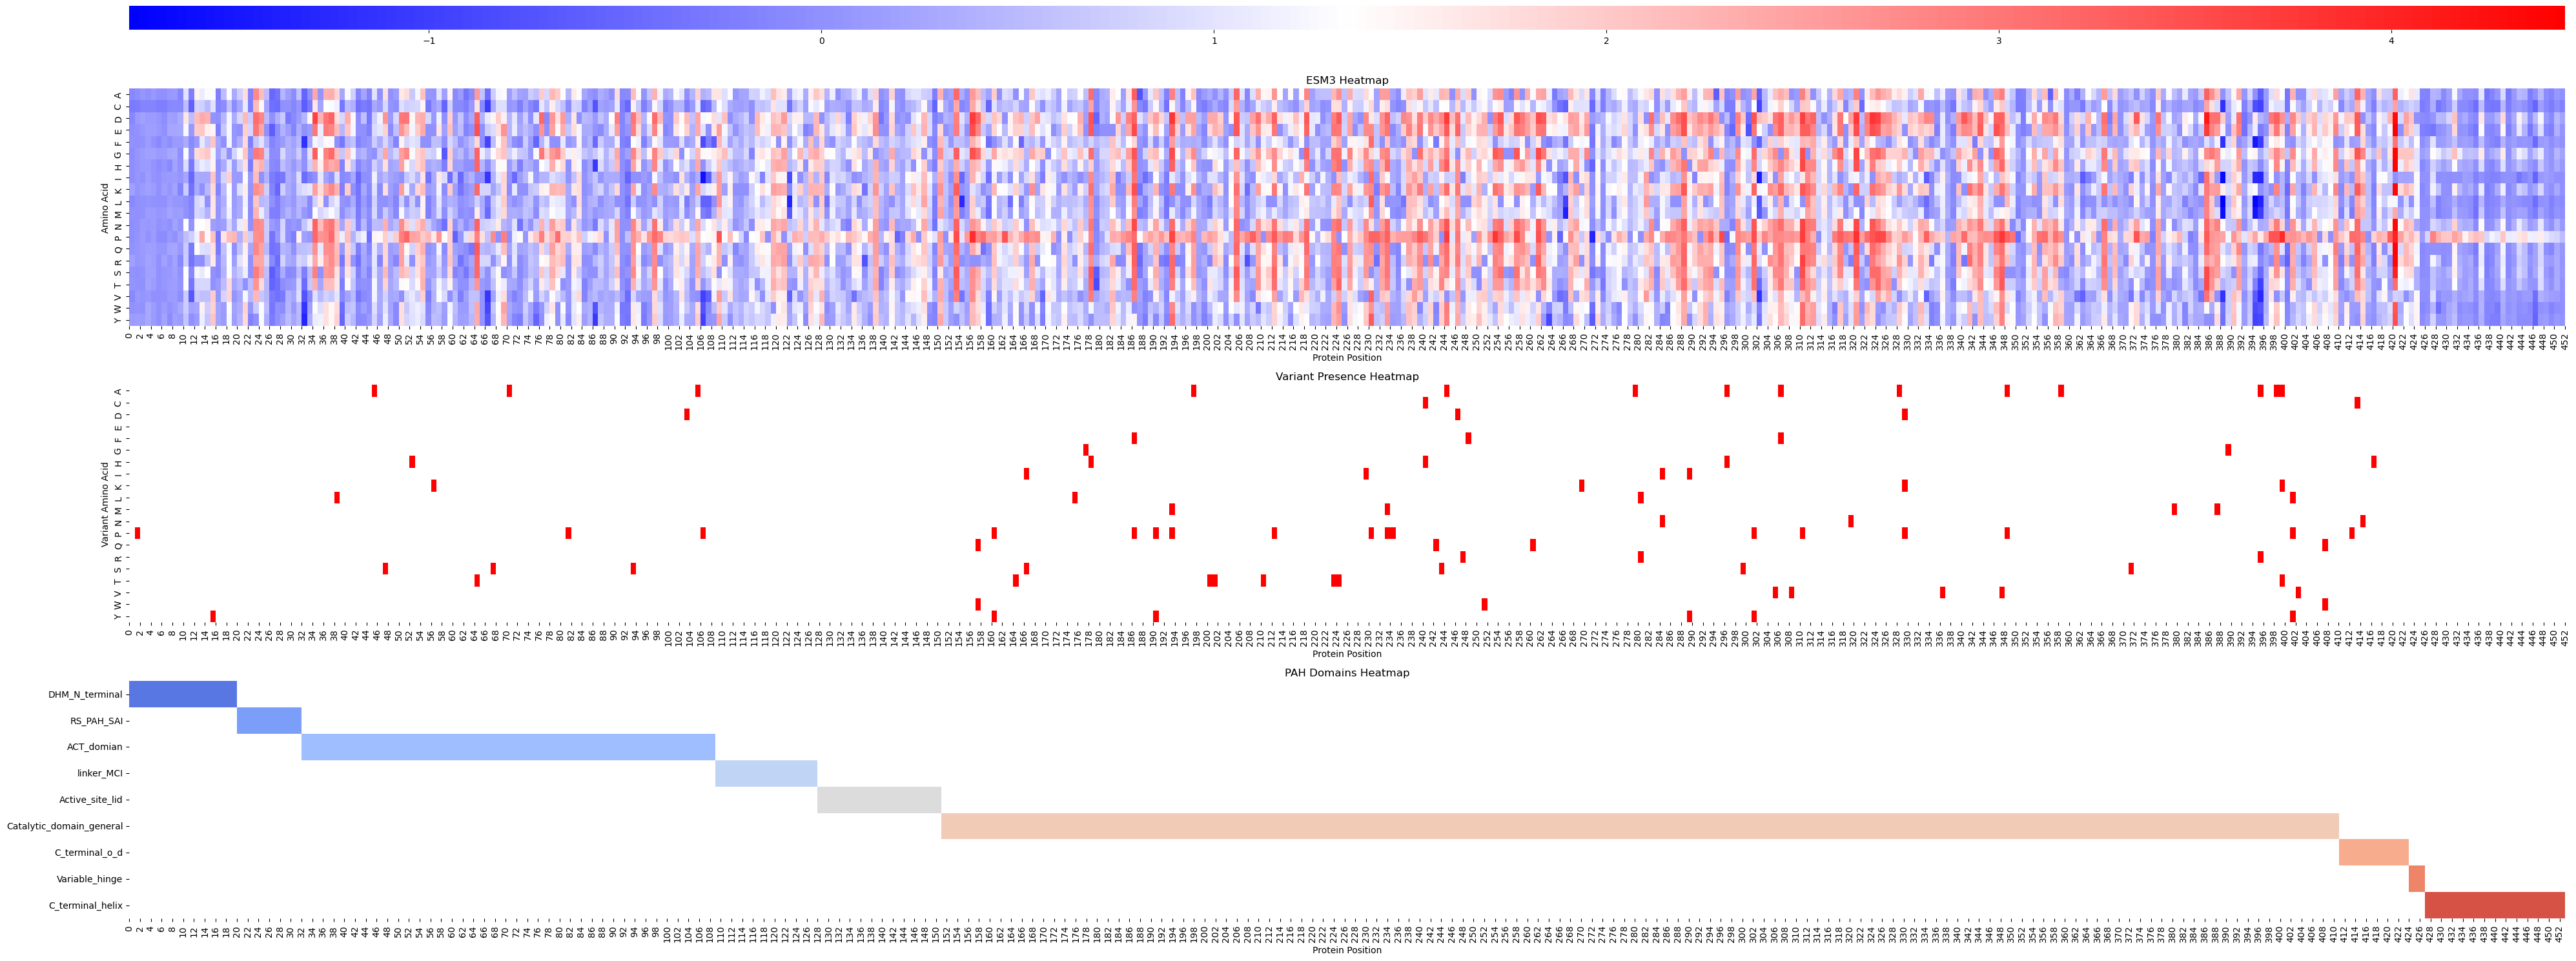

In [14]:
#Heatmap plotting

#Combine mutiple figures in one
#Define your variables: How many figures you want? 4, How many columns you want? 1
#Figure size, figure rations, applyed because of colorbar
fig, ax = plt.subplots(4, 1, figsize=(40, 15),
                      gridspec_kw={'height_ratios': [0.1, 1, 1, 1]})  

# Define x-tick positions (every 2 from 0 to 452) for all plots
xticks = np.arange(0, 453, 2)

#First plot
# Heatmap 1: ESM3/AF3 data
sns.heatmap(df_pivot_AF3,
            cmap='bwr',
            ax=ax[1],
            cbar_ax=ax[0],  # Assign colorbar to separate axis
            cbar_kws={'orientation': 'horizontal'})


ax[1].set_title('ESM3 Heatmap')
ax[1].set_xlabel('Protein Position')
ax[1].set_ylabel('Amino Acid')
ax[1].tick_params(axis='x', rotation=90)
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)

#Second plot
# Heatmap 2: Variant presence heatmap
df_PAH_variants = df_PAH_variants.drop("Aminoacid", errors='ignore')
sns.heatmap(df_PAH_variants,
            cmap=["white", "red"],
            cbar= False,
            linewidths=0.000001, linecolor='gray',
            ax=ax[2])


ax[2].set_title("Variant Presence Heatmap")
ax[2].set_xlabel("Protein Position")
ax[2].set_ylabel("Variant Amino Acid")
ax[2].tick_params(axis='x', rotation=90)
ax[2].set_xticks(xticks)
ax[2].set_xticklabels(xticks)


#Third plot

#1. Coloring data preparation
#We want our plot to have different colors per domain, so we meet to define some things first
#Define colors: white for 0 + one color per domain
#colors: Creates a Seaborn color palette with len(PAH_domains) colors, evenly spaced across the "coolwarm" gradient
#.as_hex: Converts the code into hex codes (eg.#1f77b4) which are how colors are codeed
#['white']: white as first basis color akak. prepend white: 0 = 'white'

colors = ['white'] + sns.color_palette("coolwarm", len(PAH_domains)).as_hex()
cmap_domain = ListedColormap(colors)


#2. Data definition
#Heatmap 3: PAH Domains
#Here we basically do the same that we did before, probably one time necesary only, but there different

#Create a data frame with 453 positions
#enumerate(...,starts=1): gives your domains in your dictionary a unique index starting with 1
#row[indices] = idx: sets the defined domains to an espeficic index, eg. catalitic doman AS positions 220-300 will have index 4


df_domain = pd.DataFrame(columns=range(453))
for idx, (domain_name, indices) in enumerate(PAH_domains.items(), start=1):
    row = np.zeros(453)
    row[indices] = idx  # 1, 2, 3, ... for each domain
    df_domain.loc[domain_name] = row




# Plot heatmap
sns.heatmap(df_domain.astype(float),
            cmap=cmap_domain,
            cbar=False,  # Optional: show colorbar
            linewidths=0,
            linecolor='gray',
            ax=ax[3])

ax[3].set_title("PAH Domains Heatmap")
ax[3].set_xlabel("Protein Position")
ax[3].tick_params(axis='x', rotation=90)
ax[3].set_xticks(xticks)
ax[3].set_xticklabels(xticks)


plt.tight_layout()
plt.savefig('/projectbig/jupyternotebook/jrivera/output_clean/thermompnn_results/PAH_variants_ESM3_figure.png')
plt.show()
